In [1]:
import os
mactex_path = "/Library/TeX/texbin"
if mactex_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + mactex_path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pde import PDE, FieldCollection, MemoryStorage, PolarSymGrid, ScalarField
import pandas as pd
# Enable full LaTeX rendering


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})
%load_ext autoreload
%autoreload 2

In [2]:
def merge_presets(presets, defaults):
    """Merge each preset dict with defaults; preset values take priority."""
    return {name: {**defaults, **preset} for name, preset in presets.items()}

integration_dict = {
    'outer_radius': 60,
    'num_pts_radius': 1000,
    't_max': 100,
    'dt': .001,
}
seed_dict = {
    'N_init': 50,
    'seed_radius': 5,
    'gaussian_sharpness': 3,
    'wave_cutoff': .01,
    'init_method': 'cosine_taper'
}
analysis_dict = {
    'wavefront_method':'area',
    'wavefront_cutoff':.1,
    'tracker_time':.2,
}
default_config = {
    'r': 0.5,
    'K': 50,
    'D': 0.35,
    'a': 0.03,
    'm0': 0.25,
    'h': 0.05,
    'b_r': 0.015,
    'b_k': 0.015,
    'escape': 0.5,
    'E_r0': 0.05,
    'E_k0': 0.05,
}
preset_dicts = {
    'baseline': {
        'description': 'default config'
    },
    # 'indolent_tumor': {
    #     'description': 'Slow growth, low motility, strong immune pressure. Bounded core that barely expands.',
    #     'r':.13,
    #     'D':.13,
    #     'h':.04,
    #     'b_r':.01,
    #     'b_k':.01,
    # },
    'high motility + weak niche': {
    'description': 'High growth and high motility. Rapid front propagation with weak immune containment.',
    'r':.95,
    'D':.9,
    'h':.1,
    'b_r':.005,
    'b_k':.005,
    'escape':.75,
},
'high predation/immune pressure':
{
    'description':'Strong immune attack, low escape. The lesion struggles to establish and may regress.',
    'm0':.4,
    'a':.2,
    'h':.02,
    'b_r':.01,
    'b_k':.01,
    'escape':.1,
},
'strong niche construction':
{
    'description':'Strong ecological engineering. Niche construction quickly suppresses immune pressure and lifts carrying capacity.',
    'r':.13,
    'D':.15,
    'h':.04,
    'b_r':.05,
    'b_k':.05,
}
}
bcs = {"derivative":0}
merged_presets = merge_presets(preset_dicts, default_config)
config_dict = {'integration': integration_dict, 'seed':seed_dict,'bcs':bcs,'presets': merged_presets, 'analysis':analysis_dict}

def rolling_area(u_init, r_coords):
    """Cumulative area (polar coordinates) of u_init up to each radius."""
    dr = np.gradient(r_coords)
    return np.cumsum(2 * np.pi * r_coords * u_init * dr)

def compute_wavefront_idx_by_height(u_curr, r_coords, cutoff):
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * np.max(u_curr))
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_grad(u_curr):
    du = np.gradient(u_curr)
    cutoff_idx = np.argmin(du)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_area(u_curr, r_coords, cutoff):
    roll = rolling_area(u_curr, r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1-cutoff )* total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx(config,u_curr, r_coords):
    method_dispatch = {'height':compute_wavefront_idx_by_height, 'area':compute_wavefront_idx_by_area}
    chosen_method =method_dispatch.get(config['wavefront_method'])
    return chosen_method(u_curr, r_coords, config['wavefront_cutoff'])

def compute_participation_area(u_curr):
    total_mass = u_curr.integral
    squared_mass = (u_curr**2).integral
    effective_area = (total_mass**2) / squared_mass
    return effective_area


def build_initial_N(config):
    seed_params = config['seed']
    integration_params= config['integration']
    grid = PolarSymGrid(radius=integration_params['outer_radius'], shape = integration_params['num_pts_radius'])
    r_coords = grid.axes_coords[0]

    def super_gaussian():
        exponent = 2*seed_params['gaussian_sharpness']
        u_init = np.exp(-(r_coords/seed_params['seed_radius'])**exponent)
        cutoff_idx = compute_wavefront_idx_by_height(u_init,seed_params['wave_cutoff'])
        u_init[cutoff_idx + 1:] = 0
        return u_init

    def cosine_taper():
        u_init = 1 - (r_coords/seed_params['seed_radius'])
        u_init[u_init < 0] = 0
        return u_init

    # dispatch
    method_dispatch = {'super_gaussian':super_gaussian,'cosine_taper':cosine_taper}
    chosen_method = method_dispatch.get(seed_params['init_method'])
    u_init = chosen_method()
    total = rolling_area(u_init, r_coords)[-1]
    if total == 0:
        raise ValueError("The initial distribution is zero after applying the cutoff.")
    u_init *= seed_params['N_init'] / total
    u_field = ScalarField(grid, data=u_init, label="N")
    return u_field, r_coords

def compute_phase_quantities(params):
    baseline_growth = params['r']*params['E_r0']
    m_eff = params['m0']/(1+params['escape']*((params['E_r0']+params['E_k0'])/2))
    gamma_0 = baseline_growth - (m_eff*params['a'])
    da = params['b_r'] * params['K']/np.abs(gamma_0)
    escape_crit_num = 4*(params['a']**2)*params['h']*params['m0'] * params['K']
    escape_crit_den = params['r']*((1+ params['a']*params['h']*params['K'])**2)
    escape_crit = (escape_crit_num/escape_crit_den)-1
    return gamma_0, da, escape_crit



In [3]:
scenario_wavefront_speed = []
scenario_final_profiles = []
for preset_name, preset_config in config_dict['presets'].items():
    print(f"Running simulation for preset: {preset_name}")
    u_field, r_coords = build_initial_N(config_dict)
    Er_init = np.ones_like(u_field.data) * preset_config['E_r0']
    Ek_init = np.ones_like(u_field.data) * preset_config['E_k0']
    Er_field = ScalarField(u_field.grid, data=Er_init, label="E_r")
    Ek_field = ScalarField(u_field.grid, data=Ek_init, label="E_k")
    state = FieldCollection([u_field, Er_field, Ek_field])
    print(preset_config)
    gamma_0, da, escape_crit = compute_phase_quantities(preset_config)
    print(gamma_0, da, escape_crit)
    diff = preset_config['D']
    r = preset_config['r']
    kappa = preset_config['K']
    m_0 = preset_config['m0']
    escape = preset_config['escape']
    h = preset_config['h']
    a = preset_config['a']
    b_r = preset_config['b_r']
    b_k = preset_config['b_k']
    diffusion = f"{diff} * laplace(N)"
    logistic = f"+ {r} * E_r * N * (1 - (N / (E_k * {kappa})))"
    m_eff = f"({m_0} / (1 + {escape} * ((E_r + E_k)/2)))"
    predation = f"- {m_eff} * {a} * N / (1 + {h} * {a} * N)"
    equations = {
        "N": diffusion + logistic + predation,
        "E_r": f"(1 - E_r) * (1 - exp(- {b_r} * N))",
        "E_k": f"(1 - E_k) * (1 - exp(- {b_k} * N))",
    }
    pde_system = PDE(equations, bc=config_dict['bcs'])
    storage = MemoryStorage()
    pde_system.solve(state, t_range=config_dict['integration']['t_max'],dt=config_dict['integration']['dt'], 
                     tracker=storage.tracker(.2), adaptive = True, )
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        analysis_dict = config_dict['analysis']
        idx = compute_wavefront_idx(analysis_dict, curr_u, r_coords)
        wavefront_r = r_coords[idx]
        scenario_wavefront_speed.append((preset_name,time,wavefront_r, rolling_area(curr_u, r_coords)[-1], compute_participation_area(storage[t_idx][0])))
    final_collection = storage[-1]
    final_Er = final_collection[1].data
    final_Ek = final_collection[2].data
    final_N = final_collection[0].data/(kappa*final_Ek)
    scenario_final_profiles.append((preset_name, final_N, final_Er))
    """
    show initial distribution
    turn into set of four plots
    show the wavefront top right
    show perc of initial population
    change labels
    set colors at the top
    use latex
    """

Running simulation for preset: baseline
{'r': 0.5, 'K': 50, 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
0.017682926829268295 42.41379310344827 -0.9961060032449973
Running simulation for preset: high motility + weak niche
{'r': 0.95, 'K': 50, 'D': 0.9, 'a': 0.03, 'm0': 0.25, 'h': 0.1, 'b_r': 0.005, 'b_k': 0.005, 'escape': 0.75, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'High growth and high motility. Rapid front propagation with weak immune containment.'}
0.0402710843373494 6.207928197456994 -0.9964182668391205
Running simulation for preset: high predation/immune pressure
{'r': 0.5, 'K': 50, 'D': 0.35, 'a': 0.2, 'm0': 0.4, 'h': 0.02, 'b_r': 0.01, 'b_k': 0.01, 'escape': 0.1, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'Strong immune attack, low escape. The lesion struggles to establish and may regress.'}
-0.05460199004975127 9.157175398633253 -0.9111111111111111
Running simulation for

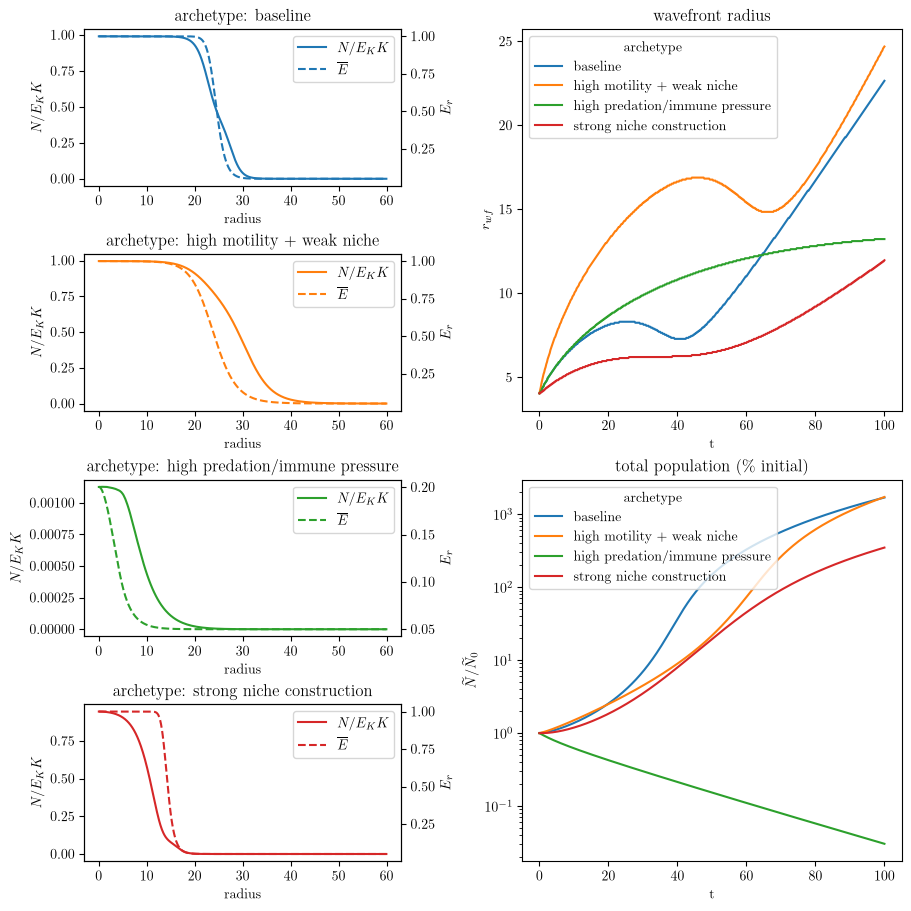

In [4]:
df = pd.DataFrame(scenario_wavefront_speed, columns = ['archetype','t','r','N','eff_area'])
df['N_init'] = config_dict['seed']['N_init']
df['N_perc'] = df['N']/df['N_init']
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
scenarios = [s for s, _, _ in scenario_final_profiles]
colors = sns.color_palette("tab10", n_colors=len(scenarios))
palette = dict(zip(scenarios, colors))
for i, (scenario, final_N, final_Er) in enumerate(scenario_final_profiles):
    ax = fig.add_subplot(gs[i, 0])
    ax_right = ax.twinx()

    line_n, = ax.plot(r_coords, final_N, color=palette[scenario], label="$N$")
    line_er, = ax_right.plot(
        r_coords, final_Er, color=palette[scenario], linestyle="--", label=r"$\bar{E}_{r}$"
    )

    ax.set_title("archetype: "+scenario)
    ax.set_xlabel("radius")
    ax.set_ylabel("$N/E_{K}K$")
    ax_right.set_ylabel(r"$E_{r}$")
    ax.legend([line_n, line_er], ["$N/E_{K}K$", r"$\overline{E}$"], loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df, x="t", y="r", hue="archetype", ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:, 1])
sns.lineplot(data=df, x="t", y="N_perc", hue="archetype", ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel("$\\widetilde{N} / \\widetilde{N}_{0}$")
ax_population.set_yscale("log")

plt.show()


# Trait-modified PDE (Fitness Gradient formalism)
In this section, use the same config_dict structure as above and implement the trait-modified PDE. Compare the leading order correction to the second-order corrections. Apply only to the "baseline" config


In [36]:
# Trait-coupled right-hand sides as py-pde f-strings.
# Derivation: trait-coupled PDE note (not in this repo), Sections 5 and 7 (Wickman et al. 2017, Appendix C,
# extended to trait-dependent motility). Traits z0, z1, z2 map to D = D0*L(z0), E_r = Er0*L(z1),
# E_K = EK0*L(z2), with L the logistic sigmoid of steepness k_j. Escape uses the rational law
# m_eff = m0/(1 + eps*Ebar), Ebar = (E_r + E_K)/2, as in the cells above.
#   second_order=False: leading-order system (Section 5.4)
#   second_order=True : full system with the second-order expectation corrections (Section 5.3)
#   escape_public     : omega in [0, 1], public share of the escape benefit (Section 2.2)

def logistic_derivs(z, k):
    """Return f-strings for L, L', ..., L^(5) of L(u) = 1/(1+exp(-k u)) at u = z."""
    L = f"(1/(1 + exp(-{k}*{z})))"
    s = f"({L}*(1 - {L}))"
    return (
        L,
        f"({k}*{s})",
        f"({k}**2*{s}*(1 - 2*{L}))",
        f"({k}**3*{s}*(1 - 6*{s}))",
        f"({k}**4*{s}*(1 - 2*{L})*(1 - 12*{s}))",
        f"({k}**5*{s}*(1 - 30*{s} + 120*{s}**2))",
    )


def build_rhs(
    *,
    r, K, a, h, m0, eps,           # ecology (eps = escape); m_eff = m0/(1 + eps*Ebar)
    D0, Er0, EK0,                  # coefficient scales
    k0, k1, k2,                    # sigmoid steepness per trait axis
    V0, V1, V2,                    # standing trait variances (diagonal)
    N_eps=1e-6,                    # regulariser for 1/N in trait equations
    second_order=True,             # True: full system (Section 5.3); False: leading order (Section 5.4)
    escape_public=0.0,             # omega in [0, 1]: 0 = private escape, 1 = public good (Section 2.2)
):
    if not 0.0 <= escape_public <= 1.0:
        raise ValueError("escape_public must lie in [0, 1]")
    w = 1.0 - escape_public                                  # private share of the escape index

    L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp = logistic_derivs("z0", k0)
    L1, L1p, L1pp, L1ppp, _, _ = logistic_derivs("z1", k1)
    L2, L2p, L2pp, L2ppp, _, _ = logistic_derivs("z2", k2)

    # coefficient fields and their trait derivatives
    D, Dp, Dpp, Dppp, Dpppp, Dppppp = (f"({D0}*{x})" for x in (L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp))
    Er, Erp, Erpp, Erppp = (f"({Er0}*{x})" for x in (L1, L1p, L1pp, L1ppp))
    EK, EKp, EKpp, EKppp = (f"({EK0}*{x})" for x in (L2, L2p, L2pp, L2ppp))

    # rational escape law and its Ebar derivatives, at Ebar(z)
    H = f"({a}/(1 + {a}*{h}*N))"
    Ebar = f"(0.5*({Er} + {EK}))"
    q = f"(1 + {eps}*{Ebar})"
    meff = f"({m0}/{q})"
    eta = f"({m0}*{eps}*{H}/(2*{q}**2))"                     # -0.5 m_E H
    kap = f"({m0}*{eps}**2*{H}/(2*{q}**3))"                  # 0.25 m_EE H
    lam = f"(-3*{m0}*{eps}**3*{H}/(4*{q}**4))"               # 0.125 m_EEE H

    # psi = -1/E_K and its chi2 derivatives
    psi1 = f"({EKp}/{EK}**2)"
    psi2 = f"({EKpp}/{EK}**2 - 2*{EKp}**2/{EK}**3)"
    psi3 = f"({EKppp}/{EK}**2 - 6*{EKp}*{EKpp}/{EK}**3 + 6*{EKp}**3/{EK}**4)"

    # per-capita fitness and selection gradients (Section 5.1)
    crowd = f"(1 - N/({K}*{EK}))"
    g = f"({r}*{Er}*{crowd} - {meff}*{H})"
    g1 = f"({Erp}*({r}*{crowd} + {w}*{eta}))"
    g2 = f"({EKp}*({r}*{Er}*N/({K}*{EK}**2) + {w}*{eta}))"

    invN = f"(1/(N + {N_eps}))"
    gN = "gradient(N)"

    if not second_order:
        # leading-order system (Section 5.4)
        rhs_N = f"{D}*laplace(N) + N*{g}"

        def transport(zi):
            return f"{D}*(laplace({zi}) + 2*dot({gN}, gradient({zi}))*{invN})"

        sorting = f"{V0}*{Dp}*laplace(N)*{invN}"
        sel1, sel2 = g1, g2
    else:
        # mean motility Dbar = <D> and its z0 derivatives (Section 5.3)
        Db = f"({D} + 0.5*{V0}*{Dpp})"
        Dbp = f"({Dp} + 0.5*{V0}*{Dppp})"                    # also <D'>, the sorting coefficient
        Dbpp = f"({Dpp} + 0.5*{V0}*{Dpppp})"
        Dbppp = f"({Dppp} + 0.5*{V0}*{Dppppp})"

        # mean fitness gbar = g + (V1 c1 + V2 c2)/2 (Section 5.1)
        c1 = f"({Erpp}*({r}*{crowd} + {eta}) - {w**2}*{kap}*{Erp}**2)"
        c2 = f"({r}*{Er}*N/{K}*{psi2} + {eta}*{EKpp} - {w**2}*{kap}*{EKp}**2)"
        gbar = f"({g} + 0.5*({V1}*{c1} + {V2}*{c2}))"

        # selection corrections S_i = <dg/dchi_i> - dg/dchi_i (Section 5.4)
        mu = f"(0.25*({V1}*{Erpp} + {V2}*{EKpp}))"
        sig2 = f"(0.25*({V1}*{Erp}**2 + {V2}*{EKp}**2))"
        S1 = (f"(0.5*{r}*({V1}*{Erppp}*{crowd} + {V2}*{Erp}*{psi2}*N/{K})"
              f" + {w}*(0.5*{V1}*{eta}*{Erppp} - 2*{kap}*{Erp}*{mu}"
              f" - {w}*{kap}*{V1}*{Erp}*{Erpp} - 2*{w**2}*{lam}*{Erp}*{sig2}))")
        S2 = (f"(0.5*{r}*N/{K}*({V2}*{Er}*{psi3} + {V1}*{Erpp}*{psi1})"
              f" + {w}*(0.5*{V2}*{eta}*{EKppp} - 2*{kap}*{EKp}*{mu}"
              f" - {w}*{kap}*{V2}*{EKp}*{EKpp} - 2*{w**2}*{lam}*{EKp}*{sig2}))")
        sel1, sel2 = f"({g1} + {S1})", f"({g2} + {S2})"

        # dN/dt = laplace(Dbar N) + N gbar   (chain-rule expanded)
        rhs_N = (f"{Db}*laplace(N) + 2*{Dbp}*dot(gradient(z0), {gN})"
                 f" + N*({Dbp}*laplace(z0) + {Dbpp}*gradient_squared(z0))"
                 f" + N*{gbar}")

        def transport(zi):
            # Dbar lap z + 2 grad(N Dbar).grad z / N
            return (f"{Db}*laplace({zi}) + 2*{Db}*dot({gN}, gradient({zi}))*{invN}"
                    f" + 2*{Dbp}*dot(gradient(z0), gradient({zi}))")

        # spatial sorting: (V0/N) laplace(N <D'>), with <D'> = Dbar'
        sorting = (f"{V0}*({Dbp}*laplace(N)*{invN} + 2*{Dbpp}*dot({gN}, gradient(z0))*{invN}"
                   f" + {Dbpp}*laplace(z0) + {Dbppp}*gradient_squared(z0))")

    return {
        "N": rhs_N,
        "z0": f"{transport('z0')} + {sorting}",          # dg/dchi0 = 0
        "z1": f"{V1}*{sel1} + {transport('z1')}",
        "z2": f"{V2}*{sel2} + {transport('z2')}",
    }

In [20]:
# Building trait_pdes skips sympy.simplify (see skip_sympy_simplify below), so construction is fast.
import contextlib
import sympy


@contextlib.contextmanager
def skip_sympy_simplify():
    """py-pde calls sympy.simplify on every RHS, which stalls on the long expressions; skip it while building the PDEs."""
    original = sympy.simplify
    sympy.simplify = lambda expr, *args, **kwargs: expr
    try:
        yield
    finally:
        sympy.simplify = original


# Trait-model settings that have no counterpart in config_dict. Values are placeholders for
# exploration, not calibrated estimates.
trait_dict = {
    'k': (3, 3, 3),     # sigmoid steepness for z0 (motility), z1 (E_r), z2 (E_K)
    'V': (0.01, 0.01, 0.01),  # standing trait variances V0, V1, V2 (low-variance closure)
    'D_max_factor': 2.0,      # plateau D0 = D_max_factor * D, so the run starts at the preset D
    'Er_max': 1.0,            # plateau of E_r; keeps E_r in [0, 1] like the E_r field above
    'EK_max': 1.0,            # plateau of E_K
    'escape_public': 1.0,     # 1.0 is closest to the place-borne E fields above; 0.0 is private escape
    'N_eps': 1e-3,            # regulariser for 1/N in the trait equations
}
trait_scenario = 'baseline'
orders = {'leading order': False, 'second order': True}


def logit(p):
    return np.log(p / (1 - p))


def build_trait_params(preset, traits):
    """Map a config_dict preset onto build_rhs arguments."""
    k0, k1, k2 = traits['k']
    V0, V1, V2 = traits['V']
    return dict(
        r=preset['r'], K=preset['K'], a=preset['a'], h=preset['h'], m0=preset['m0'],
        eps=preset['escape'],
        D0=traits['D_max_factor'] * preset['D'], Er0=traits['Er_max'], EK0=traits['EK_max'],
        k0=k0, k1=k1, k2=k2, V0=V0, V1=V1, V2=V2,
        N_eps=traits['N_eps'], escape_public=traits['escape_public'],
    )


def build_trait_state(config, preset, params):
    """Initial N from build_initial_N; uniform z chosen so D, E_r, E_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    z_init = (
        logit(preset['D'] / params['D0']) / params['k0'],
        logit(preset['E_r0'] / params['Er0']) / params['k1'],
        logit(preset['E_k0'] / params['EK0']) / params['k2'],
    )
    z_fields = [ScalarField(u_field.grid, data=np.full_like(u_field.data, z), label=f"z{i}")
                for i, z in enumerate(z_init)]
    return FieldCollection([u_field] + z_fields), r_coords


def trait_coefficients(z, k, plateau):
    """Coefficient value plateau*L(z) on the grid (leading-order value, no variance correction)."""
    return plateau / (1 + np.exp(-k * z))


trait_preset = config_dict['presets'][trait_scenario]
trait_params = build_trait_params(trait_preset, trait_dict)
with skip_sympy_simplify():
    trait_pdes = {
        order_name: PDE(build_rhs(**trait_params, second_order=flag), bc=config_dict['bcs'])
        for order_name, flag in orders.items()
    }
print(trait_preset)
print(trait_params)

{'r': 0.5, 'K': 40, 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
{'r': 0.5, 'K': 40, 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'Er0': 1.0, 'EK0': 1.0, 'k0': 3, 'k1': 3, 'k2': 3, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'N_eps': 0.001, 'escape_public': 1.0}


In [21]:
# Run the baseline preset with the leading-order and second-order systems.
# Expect a long numba compile on the first call, longest for the second-order system.
trait_wavefront = []
trait_final_profiles = []
for order_name, pde_system in trait_pdes.items():
    print(f"Running trait model ({order_name}) for preset: {trait_scenario}")
    state, r_coords = build_trait_state(config_dict, trait_preset, trait_params)
    storage = MemoryStorage()
    pde_system.solve(state, t_range=config_dict['integration']['t_max'], dt=config_dict['integration']['dt'],
                     tracker=storage.tracker(config_dict['analysis']['tracker_time']), adaptive=True)
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        idx = compute_wavefront_idx(config_dict['analysis'], curr_u, r_coords)
        trait_wavefront.append((order_name, time, r_coords[idx], rolling_area(curr_u, r_coords)[-1],
                                compute_participation_area(storage[t_idx][0])))
    final = storage[-1]
    final_D = trait_coefficients(final[1].data, trait_params['k0'], trait_params['D0'])
    final_Er = trait_coefficients(final[2].data, trait_params['k1'], trait_params['Er0'])
    final_Ek = trait_coefficients(final[3].data, trait_params['k2'], trait_params['EK0'])
    final_N = final[0].data / (trait_params['K'] * final_Ek)
    trait_final_profiles.append((order_name, final_N, final_D, final_Er, final_Ek))

Running trait model (leading order) for preset: baseline
Running trait model (second order) for preset: baseline


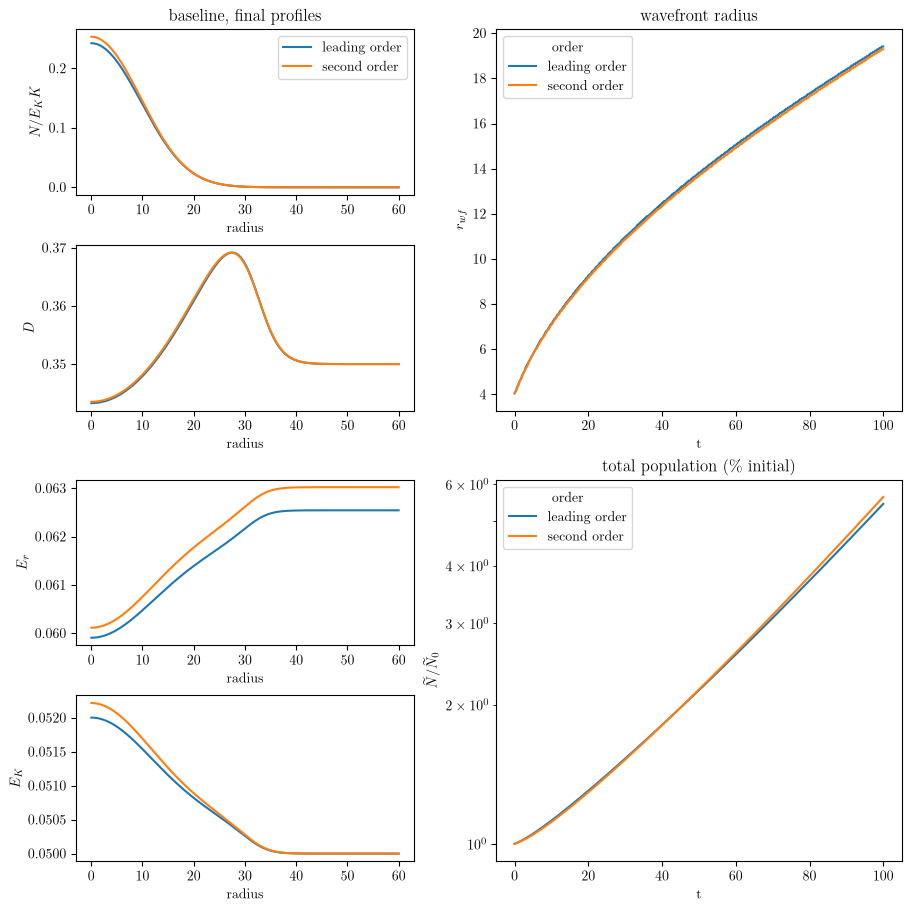

In [22]:
# Compare leading-order and second-order runs: final profiles (left), front and mass (right).
df_trait = pd.DataFrame(trait_wavefront, columns=['order', 't', 'r', 'N', 'eff_area'])
df_trait['N_init'] = config_dict['seed']['N_init']
df_trait['N_perc'] = df_trait['N'] / df_trait['N_init']
order_palette = dict(zip(orders, sns.color_palette("tab10", n_colors=len(orders))))

fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
profile_panels = [
    (1, "$N/E_{K}K$"),
    (2, "$D$"),
    (3, r"$E_{r}$"),
    (4, r"$E_{K}$"),
]
for row, (col_idx, label) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    for profile in trait_final_profiles:
        ax.plot(r_coords, profile[col_idx], color=order_palette[profile[0]], label=profile[0])
    ax.set_xlabel("radius")
    ax.set_ylabel(label)
    if row == 0:
        ax.set_title("baseline, final profiles")
        ax.legend(loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df_trait, x="t", y="r", hue="order", palette=order_palette, ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:, 1])
sns.lineplot(data=df_trait, x="t", y="N_perc", hue="order", palette=order_palette, ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel(r"$\widetilde{N} / \widetilde{N}_{0}$")
ax_population.set_yscale("log")

plt.show()

# Hybrid PDE with retained construction benefit (derivation note, Section 10.6)
$E_r$ and $E_K$ stay place-borne fields with the notebook rate law $(1-E_j)(1-e^{-\bar b_j N})$. Heritable traits $z_1$, $z_2$ set the construction rates $b_r$, $b_K$, and $z_0$ sets motility as above. A producer keeps a share $\theta_j$ of its own construction, so it experiences $E_j^{\rm exp} = E_j + A_j(b_j(\chi_j)-\bar b_j)$ with $A_j = \theta_j(1-E_j)/\bar b_j$. With $\theta_j = 0$ the construction traits are neutral, and with $V_0 = 0$ the model reduces to the non-trait PDE. Run with the second-order system for every preset in `config_dict['presets']`. An optional low-density variance gate (derivation note, Section 10.7, version B) replaces every $V_i$ by $V_i N/(N+N_c)$, so selection, spatial sorting and the $O(V)$ corrections fade where the population is absent. It is switched by `variance_gate` and `N_c` in `hybrid_dict`. The f-string builder below is the readable reference and has no gate; the runs use the hand-coded `HybridPDE` class, which implements the same equations and compiles in seconds. The f-string builder requires `logistic_derivs` from the builder cell of the previous section.

In [5]:
# Hybrid right-hand sides (derivation note, Sections 10.2 and 10.6).
# Fields: N, E_r, E_k (place-borne niche fields), z0 (motility), z1 (b_r trait), z2 (b_K trait).
# D = D0*L(z0), b_r = br0*L(z1), b_K = bK0*L(z2). Escape reads the experienced niche,
# with an optional public share omega (escape_public). theta_r, theta_K are retained shares.
#   second_order=False: leading-order system
#   second_order=True : adds the O(V) terms (Dbar, bbar, Jensen term in Gbar, full <dG/dchi>)
# Uses logistic_derivs from the builder cell of the previous section.
def logistic_derivs(z, k):
    """Return f-strings for L, L', ..., L^(5) of L(u) = 1/(1+exp(-k u)) at u = z."""
    L = f"(1/(1 + exp(-{k}*{z})))"
    s = f"({L}*(1 - {L}))"
    return (
        L,
        f"({k}*{s})",
        f"({k}**2*{s}*(1 - 2*{L}))",
        f"({k}**3*{s}*(1 - 6*{s}))",
        f"({k}**4*{s}*(1 - 2*{L})*(1 - 12*{s}))",
        f"({k}**5*{s}*(1 - 30*{s} + 120*{s}**2))",
    )


# def build_hybrid_rhs(
#     *,
#     r, K, a, h, m0, eps,           # ecology (eps = escape)
#     D0, br0, bK0,                  # plateaus of D, b_r, b_K
#     k0, k1, k2,                    # sigmoid steepness per trait axis
#     V0, V1, V2,                    # standing trait variances (diagonal)
#     theta_r, theta_K,              # retained share of own construction, in [0, 1]
#     escape_public=0.0,             # omega in [0, 1]; 0 = escape follows the experienced niche
#     N_eps=1e-6,                    # regulariser for 1/N in trait equations
#     second_order=True,
# ):
#     for name, val in (("theta_r", theta_r), ("theta_K", theta_K), ("escape_public", escape_public)):
#         if not 0.0 <= val <= 1.0:
#             raise ValueError(f"{name} must lie in [0, 1]")
#     w = 1.0 - escape_public

#     L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp = logistic_derivs("z0", k0)
#     L1, L1p, L1pp, L1ppp, _, _ = logistic_derivs("z1", k1)
#     L2, L2p, L2pp, L2ppp, _, _ = logistic_derivs("z2", k2)

#     D, Dp, Dpp, Dppp, Dpppp, Dppppp = (f"({D0}*{x})" for x in (L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp))
#     br, brp, brpp, brppp = (f"({br0}*{x})" for x in (L1, L1p, L1pp, L1ppp))
#     bK, bKp, bKpp, bKppp = (f"({bK0}*{x})" for x in (L2, L2p, L2pp, L2ppp))

#     # mean construction rates <b_j>
#     if second_order:
#         bbr = f"({br} + 0.5*{V1}*{brpp})"
#         bbK = f"({bK} + 0.5*{V2}*{bKpp})"
#     else:
#         bbr, bbK = br, bK

#     # ecology at the field values
#     H = f"({a}/(1 + {a}*{h}*N))"
#     Ebar = "(0.5*(E_r + E_k))"
#     q = f"(1 + {eps}*{Ebar})"
#     meff = f"({m0}/{q})"
#     eta = f"({m0}*{eps}*{H}/(2*{q}**2))"                     # -0.5 m_E H
#     kap = f"({m0}*{eps}**2*{H}/(2*{q}**3))"                  # 0.25 m_EE H
#     lam = f"(-3*{m0}*{eps}**3*{H}/(4*{q}**4))"               # 0.125 m_EEE H
#     crowd = f"(1 - N/({K}*E_k))"
#     g = f"({r}*E_r*{crowd} - {meff}*{H})"

#     # dG/dE_j^exp at the field values
#     Gr = f"({r}*{crowd} + {w}*{eta})"
#     GK = f"({r}*E_r*N/({K}*E_k**2) + {w}*{eta})"

#     # retained-benefit factors A_j = theta_j (1 - E_j) / bbar_j
#     Ar = f"({theta_r}*(1 - E_r)/{bbr})"
#     AK = f"({theta_K}*(1 - E_k)/{bbK})"

#     invN = f"(1/(N + {N_eps}))"
#     gN = "gradient(N)"

#     if not second_order:
#         rhs_N = f"{D}*laplace(N) + N*{g}"

#         def transport(zi):
#             return f"{D}*(laplace({zi}) + 2*dot({gN}, gradient({zi}))*{invN})"

#         sorting = f"{V0}*{Dp}*laplace(N)*{invN}"
#         sel1 = f"({Ar}*{brp}*{Gr})"
#         sel2 = f"({AK}*{bKp}*{GK})"
#     else:
#         Db = f"({D} + 0.5*{V0}*{Dpp})"
#         Dbp = f"({Dp} + 0.5*{V0}*{Dppp})"
#         Dbpp = f"({Dpp} + 0.5*{V0}*{Dpppp})"
#         Dbppp = f"({Dppp} + 0.5*{V0}*{Dppppp})"

#         # derivatives of G_j with respect to the experienced niches
#         dGr_r = f"(-{w**2}*{kap})"
#         d2Gr_r = f"(-{w**3}*{lam})"
#         d2Gr_K = f"(-2*{r}*N/({K}*E_k**3) - {w**3}*{lam})"
#         dGK_K = f"(-2*{r}*E_r*N/({K}*E_k**3) - {w**2}*{kap})"
#         d2GK_K = f"(6*{r}*E_r*N/({K}*E_k**4) - {w**3}*{lam})"
#         d2GK_r = f"(-{w**3}*{lam})"

#         # mean fitness: only the Jensen term survives
#         Gbar = (f"({g} + 0.5*({V1}*{Ar}**2*{brp}**2*{dGr_r}"
#                 f" + {V2}*{AK}**2*{bKp}**2*{dGK_K}))")

#         # full selection terms <dG/dchi_j> to O(V)
#         sel1 = (f"({Ar}*({brp}*{Gr}"
#                 f" + {V1}*(0.5*{brppp}*{Gr} + {Ar}*{brp}*{brpp}*{dGr_r} + 0.5*{Ar}**2*{brp}**3*{d2Gr_r})"
#                 f" + 0.5*{V2}*{AK}**2*{bKp}**2*{brp}*{d2Gr_K}))")
#         sel2 = (f"({AK}*({bKp}*{GK}"
#                 f" + {V2}*(0.5*{bKppp}*{GK} + {AK}*{bKp}*{bKpp}*{dGK_K} + 0.5*{AK}**2*{bKp}**3*{d2GK_K})"
#                 f" + 0.5*{V1}*{Ar}**2*{brp}**2*{bKp}*{d2GK_r}))")

#         rhs_N = (f"{Db}*laplace(N) + 2*{Dbp}*dot(gradient(z0), {gN})"
#                  f" + N*({Dbp}*laplace(z0) + {Dbpp}*gradient_squared(z0))"
#                  f" + N*{Gbar}")

#         def transport(zi):
#             return (f"{Db}*laplace({zi}) + 2*{Db}*dot({gN}, gradient({zi}))*{invN}"
#                     f" + 2*{Dbp}*dot(gradient(z0), gradient({zi}))")

#         sorting = (f"{V0}*({Dbp}*laplace(N)*{invN} + 2*{Dbpp}*dot({gN}, gradient(z0))*{invN}"
#                    f" + {Dbpp}*laplace(z0) + {Dbppp}*gradient_squared(z0))")

#     return {
#         "N": rhs_N,
#         "E_r": f"(1 - E_r)*(1 - exp(-{bbr}*N))",
#         "E_k": f"(1 - E_k)*(1 - exp(-{bbK}*N))",
#         "z0": f"{transport('z0')} + {sorting}",
#         "z1": f"{V1}*{sel1} + {transport('z1')}",
#         "z2": f"{V2}*{sel2} + {transport('z2')}",
#     }

In [6]:
# Hand-coded hybrid PDE (same equations as build_hybrid_rhs above, derivation note Sections 10.2 and 10.6).
# The f-string system is kept as the readable reference. Through PDE(...) it compiles to one flat
# sympy expression per field with the sigmoid repeated dozens of times and no common-subexpression
# elimination, so the second-order numba compile does not finish in practical time. This class
# computes the sigmoid, its derivatives and each spatial operator once per step, so it compiles in
# seconds for both orders. It is a PDEBase subclass whose make_evolution_rate is compiled by numba.
# Optional low-density variance gate (derivation note Section 10.7, version B): with
# params['variance_gate'] = True, every standing variance V_i is replaced by V_i * N/(N + N_c),
# so selection, spatial sorting and all O(V) corrections fade where the population is absent.
from pde import PDEBase
from pde.backends import get_backend


class HybridPDE(PDEBase):
    """Hybrid trait model with fields (N, E_r, E_k, z0, z1, z2) and the build_hybrid_rhs parameters.

    Extra optional params: 'variance_gate' (bool, default False) and 'N_c' (gate half-saturation density).
    """

    def __init__(self, params, second_order=True, bc=None):
        super().__init__()
        for name in ("theta_r", "theta_K", "escape_public"):
            if not 0.0 <= params[name] <= 1.0:
                raise ValueError(f"{name} must lie in [0, 1]")
        if params.get("variance_gate", False) and not params.get("N_c", 0.0) > 0.0:
            raise ValueError("N_c must be positive when variance_gate is on")
        self.params = dict(params)
        self.second_order = bool(second_order)
        self.bc = {"derivative": 0} if bc is None else bc

    def evolution_rate(self, state, t=0):
        """Uncompiled evaluation of the same right-hand side (numba grid operators), as a FieldCollection."""
        rhs = self.make_evolution_rate(state, backend=get_backend("numba"))
        out = state.copy(label="evolution rate")
        out.data[:] = rhs(state.data, t)
        return out

    def make_evolution_rate(self, state, backend):
        p = self.params
        r, K, a, h, m0, eps = p["r"], p["K"], p["a"], p["h"], p["m0"], p["eps"]
        D0, br0, bK0 = p["D0"], p["br0"], p["bK0"]
        k0, k1, k2 = p["k0"], p["k1"], p["k2"]
        V0, V1, V2 = p["V0"], p["V1"], p["V2"]
        theta_r, theta_K = p["theta_r"], p["theta_K"]
        w = 1.0 - p["escape_public"]
        N_eps = p["N_eps"]
        gate_on = bool(p.get("variance_gate", False))
        N_c = float(p.get("N_c", 1.0))

        grid = state.grid
        ops = {"backend": backend, "dtype": state.dtype}
        laplace = grid.make_operator("laplace", bc=self.bc, **ops)
        gradient = grid.make_operator("gradient", bc=self.bc, **ops)
        gradient_squared = grid.make_operator("gradient_squared", bc=self.bc, **ops)

        def ecology(N, E_r, E_k):
            """Shared ecology terms at the field values (H, eta, kappa, lambda, crowding, g)."""
            H = a / (1.0 + a * h * N)
            q = 1.0 + eps * 0.5 * (E_r + E_k)
            meff = m0 / q
            eta = m0 * eps * H / (2.0 * q**2)              # -0.5 m_E H
            kap = m0 * eps**2 * H / (2.0 * q**3)           # 0.25 m_EE H
            lam = -3.0 * m0 * eps**3 * H / (4.0 * q**4)    # 0.125 m_EEE H
            crowd = 1.0 - N / (K * E_k)
            g = r * E_r * crowd - meff * H
            Gr = r * crowd + w * eta                       # dG/dE_r^exp
            GK = r * E_r * N / (K * E_k**2) + w * eta      # dG/dE_K^exp
            return g, Gr, GK, kap, lam

        if backend.name == "numba":
            ecology = backend.compile_function(ecology)

        def pde_rhs_leading(state_data, t=0):
            N, E_r, E_k = state_data[0], state_data[1], state_data[2]
            if gate_on:
                gam = N / (N + N_c)                        # variance gate gamma(N)
            else:
                gam = np.ones_like(N)
            z0, z1, z2 = state_data[3], state_data[4], state_data[5]
            lapN, lap0, lap1, lap2 = (laplace(N), laplace(z0),
                                      laplace(z1), laplace(z2))
            gN, g1, g2 = gradient(N), gradient(z1), gradient(z2)

            # sigmoid L(k z) and derivatives, computed once per grid point
            L0 = 1.0 / (1.0 + np.exp(-k0 * z0)); s0 = L0 * (1.0 - L0)
            L1 = 1.0 / (1.0 + np.exp(-k1 * z1)); s1 = L1 * (1.0 - L1)
            L2 = 1.0 / (1.0 + np.exp(-k2 * z2)); s2 = L2 * (1.0 - L2)
            D, Dp = D0 * L0, D0 * k0 * s0
            br, brp = br0 * L1, br0 * k1 * s1
            bK, bKp = bK0 * L2, bK0 * k2 * s2

            g, Gr, GK, kap, lam = ecology(N, E_r, E_k)
            Ar = theta_r * (1.0 - E_r) / br
            AK = theta_K * (1.0 - E_k) / bK
            invN = 1.0 / (N + N_eps)

            out = np.empty_like(state_data)
            out[0] = D * lapN + N * g
            out[1] = (1.0 - E_r) * (1.0 - np.exp(-br * N))
            out[2] = (1.0 - E_k) * (1.0 - np.exp(-bK * N))
            # leading-order sorting keeps only V0 D' lap(N)/N; gated: V0 D' lap(gamma N)/N
            if gate_on:
                sort0 = V0 * Dp * laplace(gam * N) * invN
            else:
                sort0 = V0 * Dp * lapN * invN
            out[3] = D * (lap0 + 2.0 * np.sum(gN * gradient(z0), axis=0) * invN) + sort0
            out[4] = gam * V1 * Ar * brp * Gr + D * (lap1 + 2.0 * np.sum(gN * g1, axis=0) * invN)
            out[5] = gam * V2 * AK * bKp * GK + D * (lap2 + 2.0 * np.sum(gN * g2, axis=0) * invN)
            return out

        def pde_rhs_second(state_data, t=0):
            N, E_r, E_k = state_data[0], state_data[1], state_data[2]
            if gate_on:
                gam = N / (N + N_c)                        # variance gate gamma(N)
            else:
                gam = np.ones_like(N)
            V0g, V1g, V2g = V0 * gam, V1 * gam, V2 * gam   # gated variances (equal to V_i when off)
            z0, z1, z2 = state_data[3], state_data[4], state_data[5]
            lapN, lap0, lap1, lap2 = (laplace(N), laplace(z0),
                                      laplace(z1), laplace(z2))
            gN, g0 = gradient(N), gradient(z0)
            g1, g2 = gradient(z1), gradient(z2)
            gsq0 = gradient_squared(z0)

            # sigmoid L(k z) and derivatives up to L^(5), computed once per grid point
            L0 = 1.0 / (1.0 + np.exp(-k0 * z0)); s0 = L0 * (1.0 - L0)
            L1 = 1.0 / (1.0 + np.exp(-k1 * z1)); s1 = L1 * (1.0 - L1)
            L2 = 1.0 / (1.0 + np.exp(-k2 * z2)); s2 = L2 * (1.0 - L2)
            D = D0 * L0
            Dp = D0 * k0 * s0
            Dpp = D0 * k0**2 * s0 * (1.0 - 2.0 * L0)
            Dppp = D0 * k0**3 * s0 * (1.0 - 6.0 * s0)
            Dpppp = D0 * k0**4 * s0 * (1.0 - 2.0 * L0) * (1.0 - 12.0 * s0)
            Dppppp = D0 * k0**5 * s0 * (1.0 - 30.0 * s0 + 120.0 * s0**2)
            br = br0 * L1
            brp = br0 * k1 * s1
            brpp = br0 * k1**2 * s1 * (1.0 - 2.0 * L1)
            brppp = br0 * k1**3 * s1 * (1.0 - 6.0 * s1)
            bK = bK0 * L2
            bKp = bK0 * k2 * s2
            bKpp = bK0 * k2**2 * s2 * (1.0 - 2.0 * L2)
            bKppp = bK0 * k2**3 * s2 * (1.0 - 6.0 * s2)

            # O(V) mean coefficients
            bbr = br + 0.5 * V1g * brpp
            bbK = bK + 0.5 * V2g * bKpp
            Db = D + 0.5 * V0g * Dpp
            Dbp = Dp + 0.5 * V0g * Dppp
            Dbpp = Dpp + 0.5 * V0g * Dpppp
            Dbppp = Dppp + 0.5 * V0g * Dppppp

            g, Gr, GK, kap, lam = ecology(N, E_r, E_k)
            Ar = theta_r * (1.0 - E_r) / bbr
            AK = theta_K * (1.0 - E_k) / bbK
            invN = 1.0 / (N + N_eps)

            # derivatives of G_j with respect to the experienced niches
            dGr_r = -(w**2) * kap
            d2Gr_r = -(w**3) * lam
            d2Gr_K = -2.0 * r * N / (K * E_k**3) - w**3 * lam
            dGK_K = -2.0 * r * E_r * N / (K * E_k**3) - w**2 * kap
            d2GK_K = 6.0 * r * E_r * N / (K * E_k**4) - w**3 * lam
            d2GK_r = -(w**3) * lam

            # mean fitness (Jensen term) and full selection terms <dG/dchi_j> to O(V)
            Gbar = g + 0.5 * (V1g * Ar**2 * brp**2 * dGr_r + V2g * AK**2 * bKp**2 * dGK_K)
            sel1 = Ar * (brp * Gr
                         + V1g * (0.5 * brppp * Gr + Ar * brp * brpp * dGr_r + 0.5 * Ar**2 * brp**3 * d2Gr_r)
                         + 0.5 * V2g * AK**2 * bKp**2 * brp * d2Gr_K)
            sel2 = AK * (bKp * GK
                         + V2g * (0.5 * bKppp * GK + AK * bKp * bKpp * dGK_K + 0.5 * AK**2 * bKp**3 * d2GK_K)
                         + 0.5 * V1g * Ar**2 * brp**2 * bKp * d2GK_r)

            dot_N0 = np.sum(gN * g0, axis=0)
            out = np.empty_like(state_data)
            out[1] = (1.0 - E_r) * (1.0 - np.exp(-bbr * N))
            out[2] = (1.0 - E_k) * (1.0 - np.exp(-bbK * N))
            if gate_on:
                # Dbar now depends on N through gamma, so use the divergence forms:
                # lap(Dbar N), transport with grad(Dbar), sorting (1/N) lap(N V0g Dbar')
                gDb = gradient(Db)
                out[0] = laplace(Db * N) + N * Gbar
                out[3] = (Db * lap0 + 2.0 * Db * dot_N0 * invN + 2.0 * np.sum(gDb * g0, axis=0)
                          + laplace(N * V0g * Dbp) * invN)
                out[4] = (V1g * sel1 + Db * lap1 + 2.0 * Db * np.sum(gN * g1, axis=0) * invN
                          + 2.0 * np.sum(gDb * g1, axis=0))
                out[5] = (V2g * sel2 + Db * lap2 + 2.0 * Db * np.sum(gN * g2, axis=0) * invN
                          + 2.0 * np.sum(gDb * g2, axis=0))
            else:
                out[0] = (Db * lapN + 2.0 * Dbp * dot_N0
                          + N * (Dbp * lap0 + Dbpp * gsq0) + N * Gbar)
                out[3] = (Db * lap0 + 2.0 * Db * dot_N0 * invN + 2.0 * Dbp * np.sum(g0 * g0, axis=0)
                          + V0 * (Dbp * lapN * invN + 2.0 * Dbpp * dot_N0 * invN
                                  + Dbpp * lap0 + Dbppp * gsq0))
                out[4] = (V1 * sel1 + Db * lap1 + 2.0 * Db * np.sum(gN * g1, axis=0) * invN
                          + 2.0 * Dbp * np.sum(g0 * g1, axis=0))
                out[5] = (V2 * sel2 + Db * lap2 + 2.0 * Db * np.sum(gN * g2, axis=0) * invN
                          + 2.0 * Dbp * np.sum(g0 * g2, axis=0))
            return out

        return pde_rhs_second if self.second_order else pde_rhs_leading

In [ ]:
# Hybrid-model settings with no counterpart in config_dict. Values are placeholders for
# exploration, not calibrated estimates. The PDEs are second-order HybridPDE instances (cell above),
# built per preset in the run cell below.
hybrid_dict = {
    'k': (3, 3, 3),            # sigmoid steepness for z0 (motility), z1 (b_r), z2 (b_K)
    'V': (0.01, 0.01, 0.01),   # standing trait variances V0, V1, V2 (low-variance closure)
    'D_max_factor': 2.0,       # plateau D0 = D_max_factor * D, so the run starts at the preset D
    'b_max_factor': 2.0,       # plateaus b_j0 = b_max_factor * b_j, so the run starts at the preset b_j
    'theta': (0.5, 0.5),       # retained shares theta_r, theta_K; (0, 0) gives the neutral hybrid
    'escape_public': 0.5,      # omega; 0.0 means escape follows the experienced niche
    'N_eps': 1e-3,             # regulariser for 1/N in the trait equations
    'variance_gate': True,     # Section 10.7 version B: V_i -> V_i * N/(N + N_c) everywhere
    'N_c': 1e-4,               # gate half-saturation density (model units of N); keep well below the seed
}


def build_hybrid_params(preset, traits):
    """Map a config_dict preset onto HybridPDE parameters.

    build_hybrid_rhs has no gate: drop 'variance_gate' and 'N_c' before passing these to it.
    """
    k0, k1, k2 = traits['k']
    V0, V1, V2 = traits['V']
    theta_r, theta_K = traits['theta']
    return dict(
        r=preset['r'], K=preset['K'], a=preset['a'], h=preset['h'], m0=preset['m0'],
        eps=preset['escape'],
        D0=traits['D_max_factor'] * preset['D'],
        br0=traits['b_max_factor'] * preset['b_r'], bK0=traits['b_max_factor'] * preset['b_k'],
        k0=k0, k1=k1, k2=k2, V0=V0, V1=V1, V2=V2,
        theta_r=theta_r, theta_K=theta_K,
        escape_public=traits['escape_public'], N_eps=traits['N_eps'],
        variance_gate=traits['variance_gate'], N_c=traits['N_c'],
    )


def build_hybrid_state(config, preset, params):
    """Initial N from build_initial_N; E fields at E_r0, E_k0; uniform z so D, b_r, b_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    grid = u_field.grid

    def z_for(value, plateau, k):
        p = value / plateau
        return np.log(p / (1 - p)) / k

    z_init = (
        z_for(preset['D'], params['D0'], params['k0']),
        z_for(preset['b_r'], params['br0'], params['k1']),
        z_for(preset['b_k'], params['bK0'], params['k2']),
    )
    Er_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_r0']), label="E_r")
    Ek_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_k0']), label="E_k")
    z_fields = [ScalarField(grid, data=np.full_like(u_field.data, z), label=f"z{i}")
                for i, z in enumerate(z_init)]
    return FieldCollection([u_field, Er_field, Ek_field] + z_fields), r_coords


def sigmoid_value(z, k, plateau):
    """plateau*L(z) on the grid (leading-order value, no variance correction)."""
    return plateau / (1 + np.exp(-k * z))

In [ ]:
# Run every preset with the second-order hybrid system.
# A HybridPDE is built per preset (parameters differ), so each preset compiles with numba (a few seconds).
hybrid_scenario_params = {}
hybrid_scenario_wavefront_speeds = []
hybrid_scenario_final_profiles = []
for preset_name, preset_config in config_dict['presets'].items():
    print(f"Running hybrid model (second order) for preset: {preset_name}")
    params = build_hybrid_params(preset_config, hybrid_dict)
    hybrid_scenario_params[preset_name] = params
    pde_system = HybridPDE(params, second_order=True, bc=config_dict['bcs'])
    state, r_coords = build_hybrid_state(config_dict, preset_config, params)
    storage = MemoryStorage()
    pde_system.solve(
        state,
        t_range=config_dict['integration']['t_max'],
        dt=config_dict['integration']['dt'],
        tracker=['progress', storage.tracker(config_dict['analysis']['tracker_time'])],
        adaptive=True, backend='numba')
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        idx = compute_wavefront_idx(config_dict['analysis'], curr_u, r_coords)
        hybrid_scenario_wavefront_speeds.append((preset_name, time, r_coords[idx], rolling_area(curr_u, r_coords)[-1],
                                                 compute_participation_area(storage[t_idx][0])))
    final = storage[-1]
    final_Er = final[1].data
    final_Ek = final[2].data
    final_N = final[0].data / (params['K'] * final_Ek)
    final_D = sigmoid_value(final[3].data, params['k0'], params['D0'])
    final_br = sigmoid_value(final[4].data, params['k1'], params['br0'])
    final_bK = sigmoid_value(final[5].data, params['k2'], params['bK0'])
    hybrid_scenario_final_profiles.append((preset_name, final_N, final_D, final_Er, final_Ek, final_br, final_bK))

In [ ]:
# Second-order hybrid runs for all presets: final profiles (left), front and mass (right).
df_hybrid = pd.DataFrame(hybrid_scenario_wavefront_speeds, columns=['archetype', 't', 'r', 'N', 'eff_area'])
df_hybrid['N_init'] = config_dict['seed']['N_init']
df_hybrid['N_perc'] = df_hybrid['N'] / df_hybrid['N_init']
hybrid_scenarios = [profile[0] for profile in hybrid_scenario_final_profiles]
hybrid_palette = dict(zip(hybrid_scenarios, sns.color_palette("tab10", n_colors=len(hybrid_scenarios))))

fig = plt.figure(figsize=(9, 11), constrained_layout=True)
gs = fig.add_gridspec(5, 2, width_ratios=[1, 1.2])
profile_panels = [
    ((1,), ("$N/E_{K}K$",)),
    ((2,), ("$D$",)),
    ((3,), (r"$E_{r}$",)),
    ((4,), (r"$E_{K}$",)),
    ((5, 6), (r"$b_{r}$", r"$b_{K}$")),
]
for row, (col_idxs, labels) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    for profile in hybrid_scenario_final_profiles:
        for col_idx, label, style in zip(col_idxs, labels, ("-", "--")):
            ax.plot(r_coords, profile[col_idx], color=hybrid_palette[profile[0]], linestyle=style)
    ax.set_xlabel("radius")
    ax.set_ylabel(", ".join(labels))
    if row == 0:
        ax.set_title("final profiles")
    if len(col_idxs) > 1:
        # line style legend only; preset colours are in the wavefront legend
        style_handles = [plt.Line2D([], [], color="0.3", linestyle=style) for style in ("-", "--")]
        ax.legend(style_handles, labels, loc="center right", fontsize="small")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df_hybrid, x="t", y="r", hue="archetype", palette=hybrid_palette, ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:4, 1])
sns.lineplot(data=df_hybrid, x="t", y="N_perc", hue="archetype", palette=hybrid_palette, ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel(r"$\widetilde{N} / \widetilde{N}_{0}$")
ax_population.set_yscale("log")
ax_population.get_legend().remove()

gate_label = f"variance gate $N_c$={hybrid_dict['N_c']:g}" if hybrid_dict['variance_gate'] else "no variance gate"
fig.suptitle(f"second-order hybrid model, all presets ({gate_label})")

plt.show()

In [ ]:
df_hybrid[df_hybrid['archetype']=='strong niche construction']

In [17]:
df[df['archetype']=='strong niche construction']

,archetype,t,r,N,eff_area,N_init,N_perc
1503,strong niche construction,0.0,4.05,50.000000,52.358588,50,1.000000
1504,strong niche construction,0.2,4.05,49.972971,53.096261,50,0.999459
1505,strong niche construction,0.4,4.11,49.957529,53.814151,50,0.999151
1506,strong niche construction,0.6,4.11,49.953352,54.520241,50,0.999067
1507,strong niche construction,0.8,4.17,49.960105,55.217147,50,0.999202
...,...,...,...,...,...,...,...
1999,strong niche construction,99.2,11.85,16998.386994,490.771765,50,339.967740
2000,strong niche construction,99.4,11.85,17109.858104,493.328968,50,342.197162
2001,strong niche construction,99.6,11.91,17221.685356,495.895005,50,344.433707
2002,strong niche construction,99.8,11.91,17333.862307,498.469089,50,346.677246
